In [92]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


## Loading in the data

In [15]:
url='https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv'
df=pd.read_csv(url)
print(df.head())

                 track_id                                         track_name  \
0  6f807x0ima9a1j3VPbc7VN  I Don't Care (with Justin Bieber) - Loud Luxur...   
1  0r7CVbZTWZgbTCYdfa2P31                    Memories - Dillon Francis Remix   
2  1z1Hg7Vb0AhHDiEmnDE79l                    All the Time - Don Diablo Remix   
3  75FpbthrwQmzHlBJLuGdC7                  Call You Mine - Keanu Silva Remix   
4  1e8PAfcKUYoKkxPhrHqw4x            Someone You Loved - Future Humans Remix   

       track_artist  track_popularity          track_album_id  \
0        Ed Sheeran                66  2oCs0DGTsRO98Gh5ZSl2Cx   
1          Maroon 5                67  63rPSO264uRjW1X5E6cWv6   
2      Zara Larsson                70  1HoSmj2eLcsrR0vE9gThr4   
3  The Chainsmokers                60  1nqYsOef1yKKuGOVchbsk6   
4     Lewis Capaldi                69  7m7vv9wlQ4i0LFuJiE2zsQ   

                                    track_album_name track_album_release_date  \
0  I Don't Care (with Justin Bieber) [Loud Luxu

## Transformed outcome variable

In [17]:
df['track_popularity_shifted'] = np.where(df.track_popularity == 100, df.track_popularity - 0.1, df.track_popularity)
df['track_popularity_shifted'] = np.where(df.track_popularity == 0, df.track_popularity + 0.1, df.track_popularity_shifted)
df['track_popularity_fraction'] = df.track_popularity_shifted/100
df['track_popularity_transformed'] = np.log(df.track_popularity_fraction / (1 - df.track_popularity_fraction))



In [23]:
df = df.drop(['track_popularity', 'track_popularity_shifted', 'track_popularity_fraction'], axis=1, errors='ignore')
#without ignore errors code gave me error as if the columns did not exist 

In [34]:
df.columns #making sure the correct columns were removed

Index(['track_id', 'track_name', 'track_artist', 'track_album_id',
       'track_album_name', 'track_album_release_date', 'playlist_name',
       'playlist_id', 'playlist_genre', 'playlist_subgenre', 'danceability',
       'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms',
       'track_popularity_transformed'],
      dtype='object')

In [36]:
df.head()

,track_id,track_name,track_artist,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,track_popularity_transformed
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,...,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,0.663294
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,...,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,0.708185
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,...,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,0.847298
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,...,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093,0.405465
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,...,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052,0.800119


## 2) Initial exploration 

In [28]:
df.shape # number of rows and columns

(32833, 23)

In [29]:
df.info() #column names and associated data types


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   track_id                      32833 non-null  object 
 1   track_name                    32828 non-null  object 
 2   track_artist                  32828 non-null  object 
 3   track_album_id                32833 non-null  object 
 4   track_album_name              32828 non-null  object 
 5   track_album_release_date      32833 non-null  object 
 6   playlist_name                 32833 non-null  object 
 7   playlist_id                   32833 non-null  object 
 8   playlist_genre                32833 non-null  object 
 9   playlist_subgenre             32833 non-null  object 
 10  danceability                  32833 non-null  float64
 11  energy                        32833 non-null  float64
 12  key                           32833 non-null  int64  
 13  l

In [33]:
df.isna().sum() # number of missing valuse in each column 

track_id                        0
track_name                      5
track_artist                    5
track_album_id                  0
track_album_name                5
track_album_release_date        0
playlist_name                   0
playlist_id                     0
playlist_genre                  0
playlist_subgenre               0
danceability                    0
energy                          0
key                             0
loudness                        0
mode                            0
speechiness                     0
acousticness                    0
instrumentalness                0
liveness                        0
valence                         0
tempo                           0
duration_ms                     0
track_popularity_transformed    0
dtype: int64

df.nunique() # number of unique values  in each column 

# Treatment of Variables 
Track ID and track album ID are not usuesul for visualization due to the high number of uniquie values. Charts using these variables might be hard to read due to overcrowding. I would like to focus on tempo, loudness, energy, track popularity, playlist genre and key.
## Continuous variables: tempo, loudness, energy and track popularity
## Catergorical variables: key and playlist genre 
Key has numerical variables that I will be using as categorical because the number relates to a key not a continuous variable. 

In [ ]:
print(df['key'].head())


## Summary Statistics 

In [38]:
# count of unique values in each categorical variable 
print(df['playlist_genre'].value_counts())
print(df['key'].value_counts())

playlist_genre
edm      6043
rap      5746
pop      5507
r&b      5431
latin    5155
rock     4951
Name: count, dtype: int64
key
1     4010
0     3454
7     3352
9     3027
11    2996
2     2827
5     2680
6     2670
8     2430
10    2273
4     2201
3      913
Name: count, dtype: int64


In [41]:
continuous_cols = ['tempo', 'loudness', 'energy', 'track_popularity_transformed']
stats = df[continuous_cols].agg(['mean', 'min', 'max', 'std'])
stats

,tempo,loudness,energy,track_popularity_transformed
mean,120.881132,-6.719499,0.698619,-0.827397
min,0.000000,-46.448000,0.000175,-6.906755
max,239.440000,1.275000,1.000000,6.906755
std,26.903624,2.988436,0.180910,2.212342


## Marginal Distributions

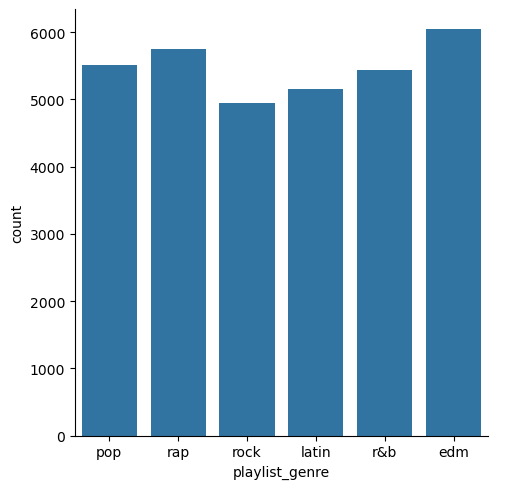

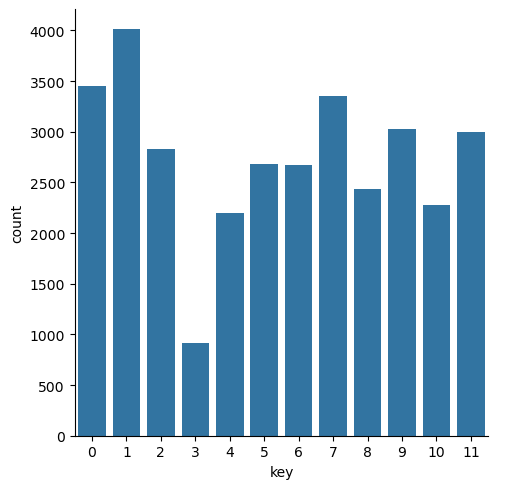

In [48]:
#Categorical variable bar charts
sns.catplot(data= df, x='playlist_genre', kind ='count')
sns.catplot(data= df, x='key', kind ='count')
plt.show()

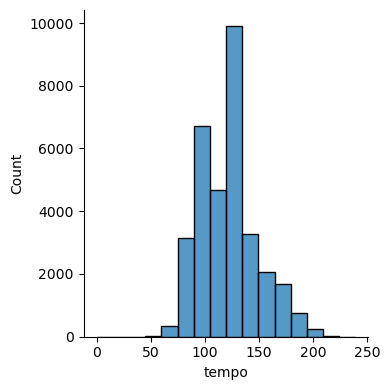

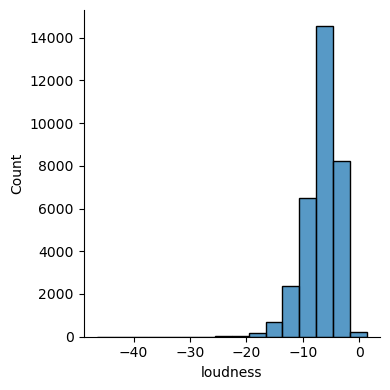

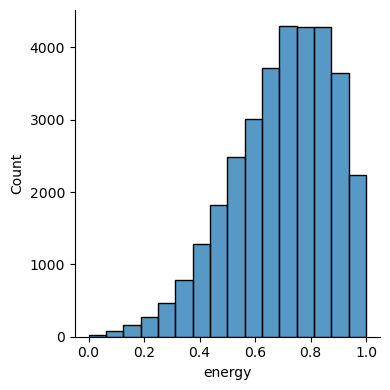

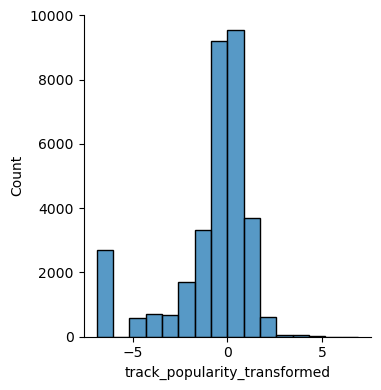

In [65]:
sns.displot(data=df, x='tempo', bins=16, height=4)
sns.displot(data=df, x='loudness', bins=16, height=4)
sns.displot(data=df, x='energy', bins=16, height=4)
sns.displot(data=df, x='track_popularity_transformed', bins=16, height=4)

# Categorical vs categorical can be plotted by count plots, grouped bar charts or heatmaps.
countplots show the number of rows in each catagory and are useful when there are a smaall amount of unique values. I chose to use a heatmap because it offers the best visual representation.

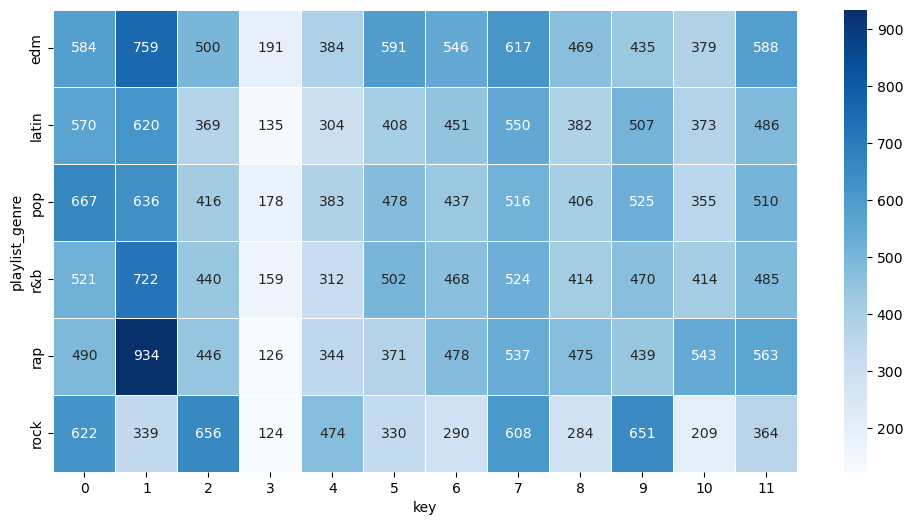

In [70]:
#Categorical to categorical 
genre_key_counts = pd.crosstab(df['playlist_genre'], df['key'])
plt.figure(figsize=(12, 6))
sns.heatmap( genre_key_counts, 
    annot=True,      # Displays the exact track count inside each square
    fmt='d',         # Formats annotations as whole integers
    cmap='Blues',    # 
    linewidths=0.5)
plt.show()

## Categorical to continuous
I chose a violin plot to represent the data because it shows skewed data that is not always represented in other types of plots. This plot shows energy in correlation to playlist genre and multiple peaks are represented.  By reading this plot I can determine that EDM typically has songs with more energy than other genres. This plot also show cases that r&b has a wide range or energy levels but the median is below all other genres. 

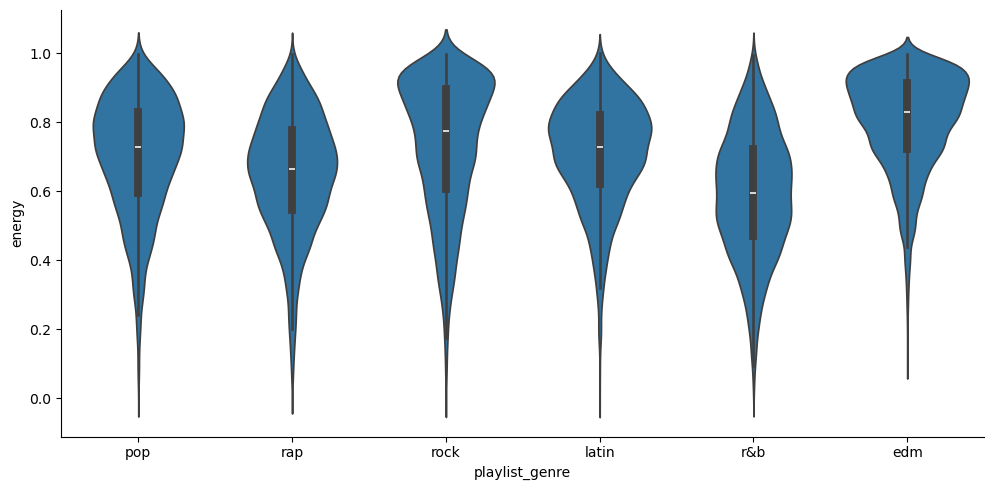

In [117]:
#categorical vs continuous 
sns.catplot(data=df, x='playlist_genre', y='energy', kind='violin', aspect=2)

## Categorical to Continuous
There doesnt seem to be a direct correlation bewteen key and loudness. For example, a higher key doesnt seem to mean the sound is louder. 


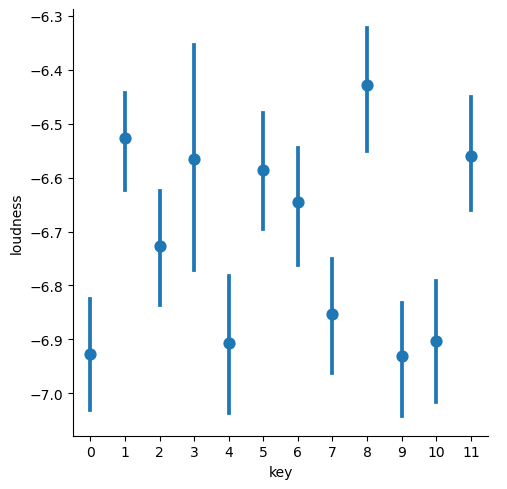

In [82]:
sns.catplot(data=df, x='key', y='loudness', kind='point', linestyle='none', height=5)
plt.show()

## Continuous to Continuous 
There are a lot of continuous variables so the plot gets very busy, but the correlation between the variables in this scatterplot is very easy to see. For all genres there is a there is a positive correlation bewteen loudness and energy. This also helps visualise questions number 7 that the correlation of loudness to energy does not change across groups. 

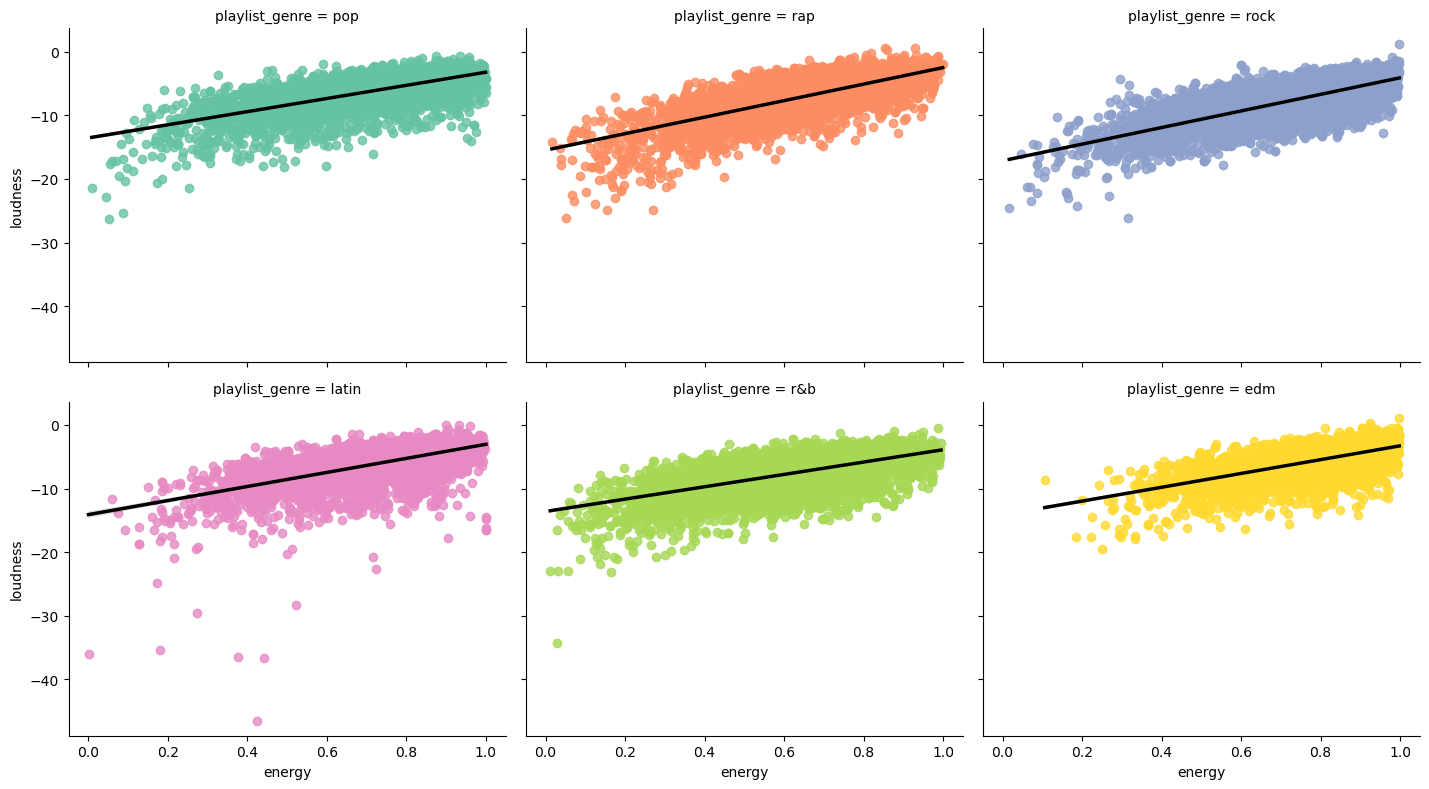

In [113]:
sns.lmplot(data=df, x='energy', 
    y='loudness', 
    col='playlist_genre',    # divides each genre
    col_wrap=3,              # 3 charts rows 
    hue='playlist_genre',    # colors
    palette='Set2', 
    height=4,                # plot height
    aspect=1.2, line_kws={ 'color':'black','linewidth': 2.5})
plt.show()

    

## Relationships grouped by categorical variables
The relationship between tempo and track popularity correlation kinda changes a bit between groups. For example a higher tempo in EDM has a negative correlation on track popularity, but for r&b tempo does not seem to effect track popularity. 

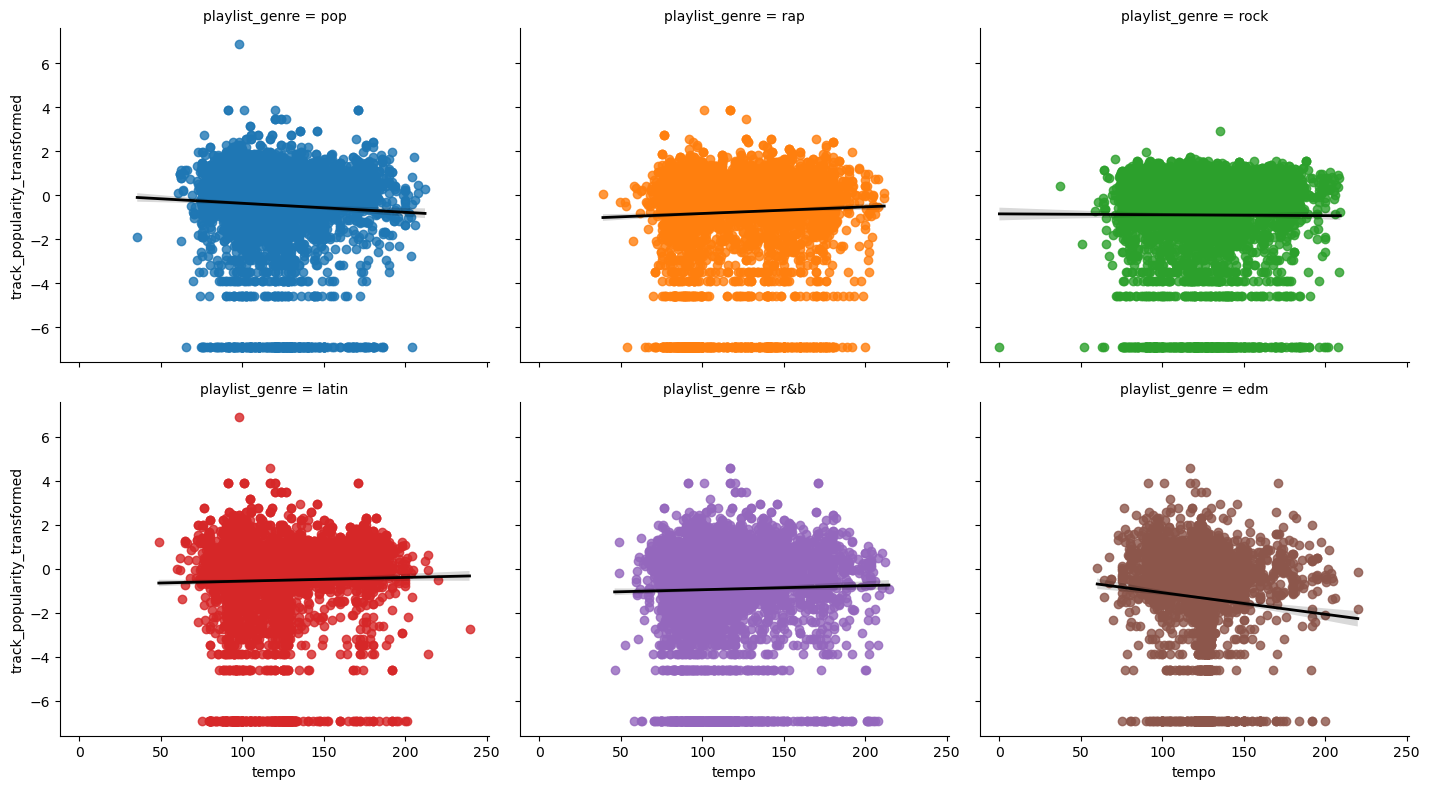

In [115]:
# Faceted scatter plot in each genre
sns.lmplot(
    data=df, x='tempo', y='track_popularity_transformed', col='playlist_genre',
    col_wrap=3,
    hue='playlist_genre',
    height=4,
    aspect=1.2, line_kws={'color': 'black', 'linewidth': 2}
    )
plt.show()

## Based on my visual analysis I think Tempo, loudness and energy. I dont feel like I really looked at song popularity in relationship to different variables often. I did compare track popularity to tempo which changed across diferent genres, which I will think will be important in the outcome variable. I think to look at song popularity I would need to include more variables to look at. Overall, I found it interesting that the higher the key did not mean the louder the track is. I feel often we associate a louder pitch to hurt your ears and the plot chart visualized neither a negtive or positive correlation. 